<a href="https://colab.research.google.com/github/Lois-coder1/Renewables/blob/main/Copy_of_predicting_solar_generation_potential.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#The aim of this model is to accurately predict daily solar irrandiance in various Nigerian cities/climatic zones using historical meteorological data from NASA POWER API.
#To estimate per-capita solar generation potential when compared to demand.
#Consequently, identify which area would most benefit from solar energy investment.

Total rows: 40183
        date  ALLSKY_SFC_SW_DWN  CLRSKY_SFC_SW_DWN    T2M   RH2M  PRECTOTCORR  \
0 2015-01-01             5.7622             5.7854  25.23  68.26          0.0   
1 2015-01-02             6.0350             6.0478  26.16  73.23          0.0   
2 2015-01-03             5.3186             5.3717  25.66  78.71          0.0   
3 2015-01-04             5.8462             5.8870  24.11  63.66          0.0   
4 2015-01-05             5.1638             5.2082  23.40  59.45          0.0   

   CLOUD_AMT   city        zone  population  
0       6.89  Lagos  South West       15.39  
1       5.16  Lagos  South West       15.39  
2       6.21  Lagos  South West       15.39  
3       7.54  Lagos  South West       15.39  
4      11.66  Lagos  South West       15.39  
GHI                 0
clear_sky_GHI       0
temp_c              0
humidity_percent    0
precipitation_mm    0
cloud_percent       0
dtype: int64
Features created. DataFrame shape: (40183, 17)
['date', 'GHI', 'clear_sky_

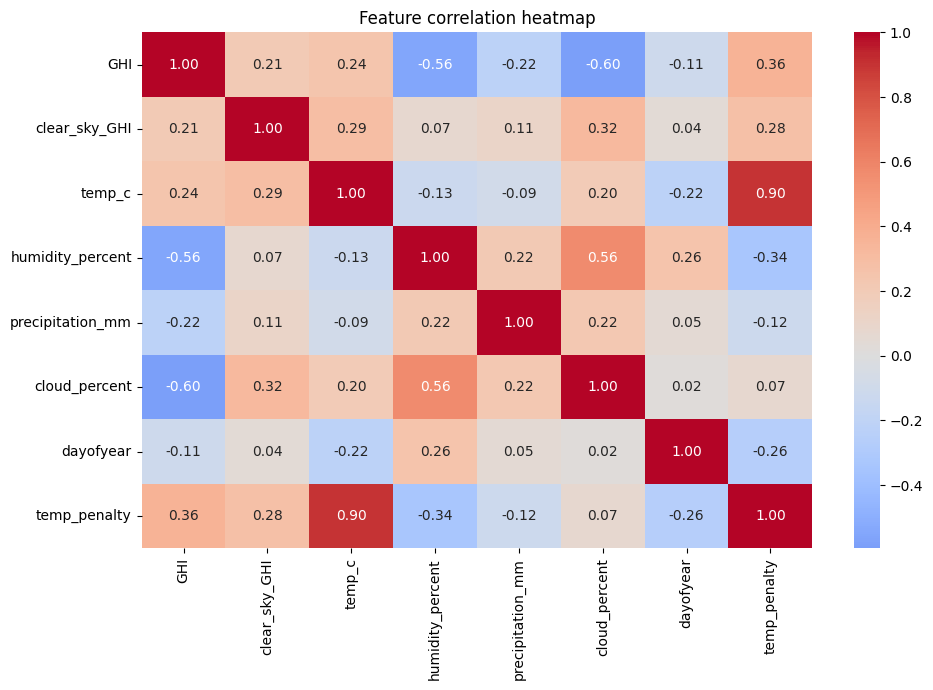

Linear Regression          RMSE: 0.6635  R²: 0.6657
Random Forest              RMSE: 0.5451  R²: 0.7743
Gradient Boosting          RMSE: 0.5476  R²: 0.7722
Mean GHI (test set): 5.17 W/m²
Best model: Random Forest
nRMSE (Random Forest): 10.55%
         feature  importance
   cloud_percent    0.492289
   clear_sky_GHI    0.166151
humidity_percent    0.160108
       dayofyear    0.046328
precipitation_mm    0.032621
          temp_c    0.031831
         zoneenc    0.025932
    temp_penalty    0.022383
         cityenc    0.016130
           month    0.004345
       seasonenc    0.001882


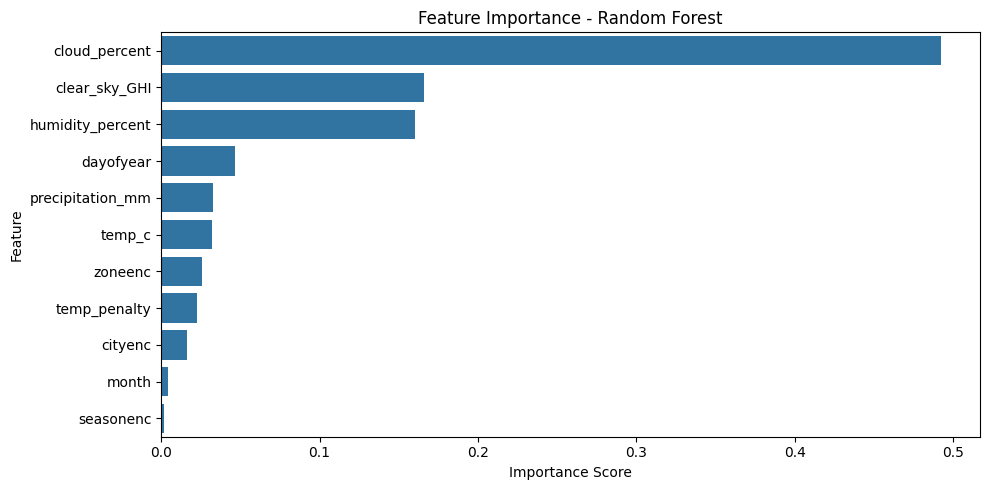

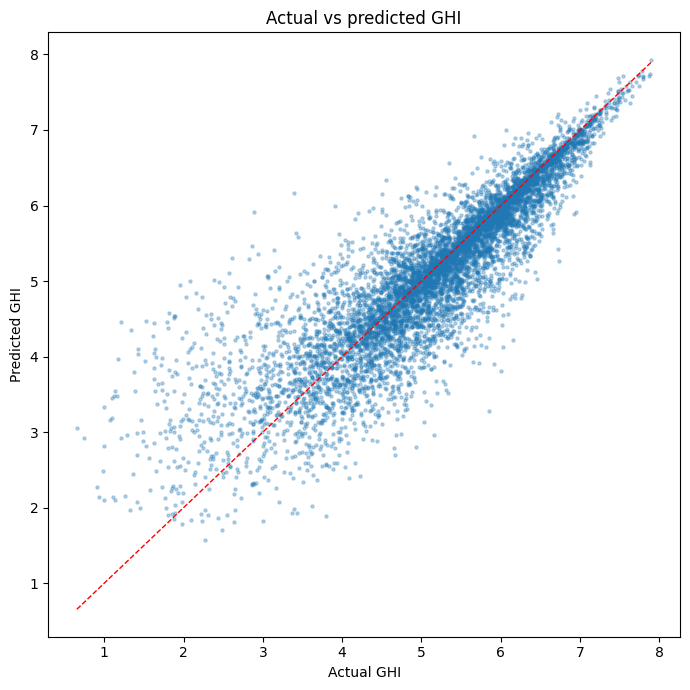

CV R² scores: [0.598 0.63  0.691 0.736 0.705]
Mean R²: 0.672 ± 0.050
             city        r2
1      Benin City  0.625403
6           Lagos  0.627892
9   Port Harcourt  0.647024
3          Ilorin  0.676653
8         Makurdi  0.699060
2           Enugu  0.708460
0           Abuja  0.713981
5            Kano  0.743694
7       Maiduguri  0.759867
10         Sokoto  0.764575
4             Jos  0.770473
         city          zone  avg_GHI  annual_kwh_m2
         Kano    North West 5.931509     251.590165
       Sokoto    North West 5.935607     250.269484
    Maiduguri    North East 5.902032     246.197781
          Jos North Central 5.286343     230.631640
        Abuja North Central 5.249369     226.397693
       Ilorin North Central 5.039745     218.203187
      Makurdi North Central 5.060072     217.202513
        Enugu    South East 4.764495     206.161787
        Lagos    South West 4.602055     197.545329
   Benin City   South South 4.461232     193.451089
Port Harcourt   South S

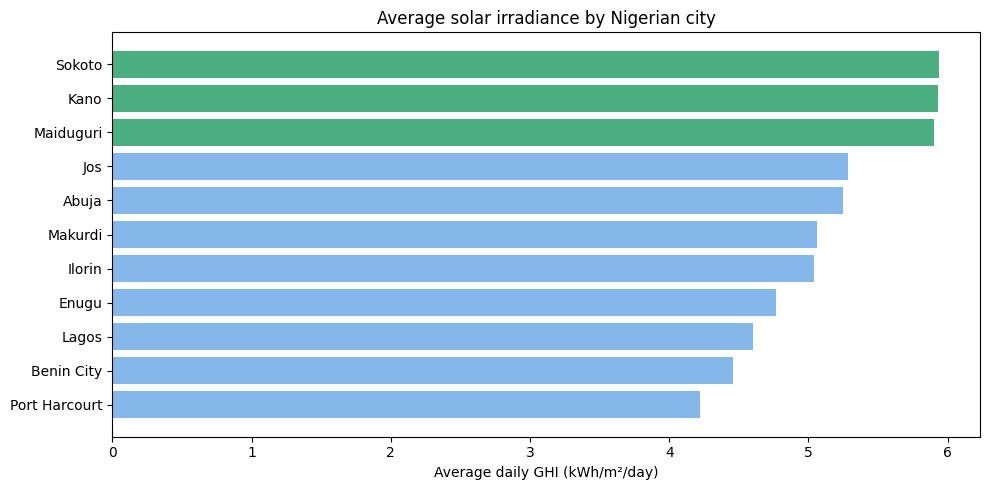

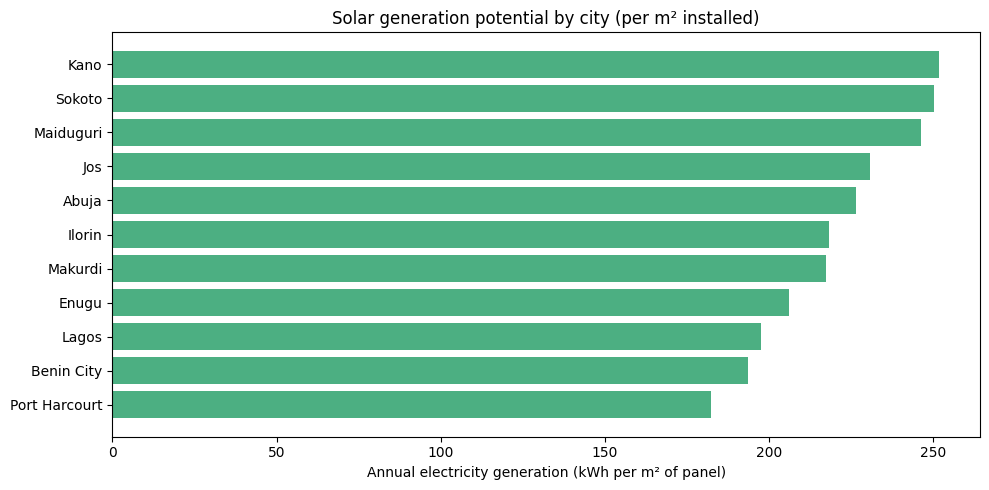

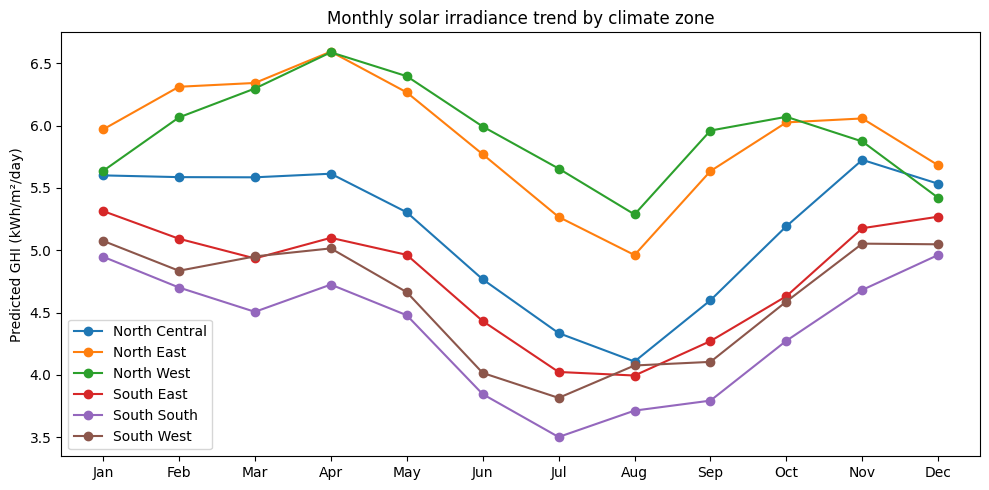

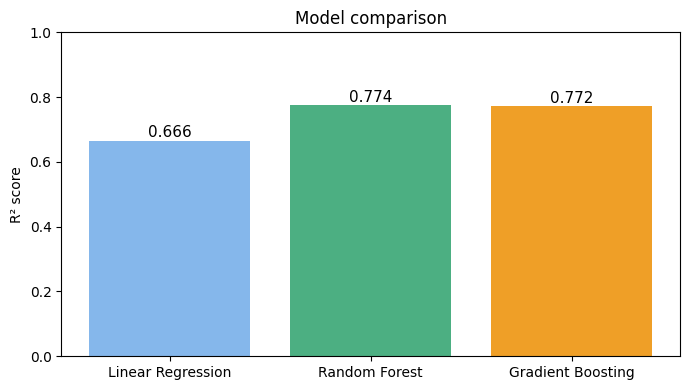

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings('ignore')

#all cities used in model
# population in millions
cities = {
    'Lagos':         {'lat': 6.5244,  'lon': 3.3792,  'zone': 'South West',    'population': 15.39},
    'Port Harcourt': {'lat': 4.8472,  'lon': 6.9746,  'zone': 'South South',   'population':  2.12},
    'Benin City':    {'lat': 6.3350,  'lon': 5.6037,  'zone': 'South South',   'population':  2.12},
    'Enugu':         {'lat': 6.4483,  'lon': 7.5139,  'zone': 'South East',    'population':  0.90},
    'Ilorin':        {'lat': 8.5373,  'lon': 4.5444,  'zone': 'North Central', 'population':  1.00},
    'Abuja':         {'lat': 9.0563,  'lon': 7.4985,  'zone': 'North Central', 'population':  2.69},
    'Makurdi':       {'lat': 7.7322,  'lon': 8.5391,  'zone': 'North Central', 'population':  0.40},
    'Jos':           {'lat': 9.9231,  'lon': 8.8967,  'zone': 'North Central', 'population':  1.00},
    'Kano':          {'lat': 12.0022, 'lon': 8.5920,  'zone': 'North West',    'population':  4.91},
    'Sokoto':        {'lat': 13.0059, 'lon': 5.2476,  'zone': 'North West',    'population':  0.60},
    'Maiduguri':     {'lat': 11.8311, 'lon': 13.1510, 'zone': 'North East',    'population':  1.20},
}

#retrieving the data from NASA POWER
url = "https://power.larc.nasa.gov/api/temporal/daily/point"

def citydata(city_name, lat, lon):
  params = {
    "parameters": "ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,RH2M,PRECTOTCORR,CLOUD_AMT",
    "community":  "RE",
    "longitude":  lon,
    "latitude":   lat,
    "start":      "20150101",
    "end":        "20241231",
    "format":     "JSON"
  }

  response = requests.get(url, params=params, timeout=60)
  data = response.json()["properties"]["parameter"]

  df = pd.DataFrame(data)
  df.index = pd.to_datetime(df.index, format="%Y%m%d")
  df.index.name = "date"
  df["city"] = city_name
  return df.reset_index()

#Dataframe creation
all_dfs = []
for name, info in cities.items():
  df = citydata(name, info["lat"], info["lon"])
  df ['zone'] = info['zone']
  df ['population'] = info['population']
  all_dfs.append(df)

rawdf = pd.concat(all_dfs, ignore_index=True)
print(f"Total rows: {len(rawdf)}")
print(rawdf.head())

df = rawdf.copy()
df.rename(columns= {
    'ALLSKY_SFC_SW_DWN': 'GHI',
    'CLRSKY_SFC_SW_DWN': 'clear_sky_GHI',
    'T2M':               'temp_c',
    'RH2M':              'humidity_percent',
    'PRECTOTCORR':       'precipitation_mm',
    'CLOUD_AMT':         'cloud_percent'
}, inplace=True)

#data cleaning
df.replace(-999, np.nan, inplace=True)
print(df[['GHI', 'clear_sky_GHI', 'temp_c', 'humidity_percent', 'precipitation_mm', 'cloud_percent']].isna().sum())

#data is not missing values
#values may have already been filled in

#introducing dating and seasons
df['month'] = df['date'].dt.month
df['dayofyear'] = df['date'].dt.dayofyear
def seasons(row):
  d = row['date'].month
  z = row['zone']
  if 'North' in z:
    return 'dry' if d in [10,11,12,1,2,3,4] else 'wet'
  else:
    return 'dry' if d in [12,1,2,3] else 'wet'

df['season'] = df.apply(seasons, axis = 1)

# temperature penalty on panel efficiency
# panels lose ~0.4% efficiency per degree above 25°C
df["temp_penalty"] = df["temp_c"].apply(lambda t: max(0, 3 * (t - 25) * 0.004))

# encoding categorical columns
le_city   = LabelEncoder()
le_zone   = LabelEncoder()
le_season = LabelEncoder()
df["cityenc"]   = le_city.fit_transform(df["city"])
df["zoneenc"]   = le_zone.fit_transform(df["zone"])
df["seasonenc"] = le_season.fit_transform(df["season"])

print("Features created. DataFrame shape:", df.shape)
print(df.columns.tolist())

#creating the model
FEATURES = [
    'month', 'dayofyear', 'temp_c', 'humidity_percent', 'precipitation_mm', 'cloud_percent',
    'clear_sky_GHI', 'temp_penalty', 'cityenc', 'zoneenc', 'seasonenc'
]

corr_cols = ['GHI', 'clear_sky_GHI', 'temp_c', 'humidity_percent',
             'precipitation_mm', 'cloud_percent', 'dayofyear', 'temp_penalty']

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0)
plt.title('Feature correlation heatmap')
plt.tight_layout()
plt.show()

TARGET = 'GHI'

x = df[FEATURES]
y = df[TARGET]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=67
)

models = {
    "Linear Regression":     LinearRegression(),
    "Random Forest":         RandomForestRegressor(n_estimators=100, random_state=67, n_jobs=-1),
    "Gradient Boosting":     GradientBoostingRegressor(n_estimators=100, random_state=67),
}

results = {}
for name, model in models.items():
    model.fit(x_train, y_train)
    preds = model.predict(x_test)
    rmse  = np.sqrt(mean_squared_error(y_test, preds))
    r2    = r2_score(y_test, preds)
    results[name] = {"model": model, "rmse": rmse, "r2": r2, "preds": preds}
    print(f"{name:25s}  RMSE: {rmse:.4f}  R²: {r2:.4f}")


print(f"Mean GHI (test set): {y_test.mean():.2f} W/m²")

#specifically stating the best model
best_model_name = max(results, key=lambda k: results[k]["r2"])
best_model = results[best_model_name]["model"]
print(f"Best model: {best_model_name}")

preds = best_model.predict(x_test)

#specific random forest results
rf_rmse = results["Random Forest"]["rmse"]
print(f"nRMSE (Random Forest): {(rf_rmse / y_test.mean()) * 100:.2f}%")

#feature importance assessing
rf_model = results["Random Forest"]["model"]
importance_df = pd.DataFrame({
    "feature": FEATURES,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print(importance_df.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x="importance", y="feature")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("featureimportancerf.png", dpi=150)
plt.show()

#visualisation 1
plt.figure(figsize=(7,7))
plt.scatter(y_test, preds, alpha=0.3, s=5)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--', linewidth=1)
plt.xlabel("Actual GHI")
plt.ylabel("Predicted GHI")
plt.title("Actual vs predicted GHI")
plt.tight_layout()
plt.show()


#r2 cross-validation
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(best_model, x, y, cv=5, scoring='r2', n_jobs=-1)
print(f"CV R² scores: {cv_scores.round(3)}")
print(f"Mean R²: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

#city checks
df_test = x_test.copy()
df_test["actual"]    = y_test.values
df_test["predicted"] = preds
df_test["city"]      = df.loc[x_test.index, "city"].values

city_errors = df_test.groupby("city").apply(
    lambda g: r2_score(g["actual"], g["predicted"])
).reset_index()
city_errors.columns = ["city", "r2"]
print(city_errors.sort_values("r2"))

PANEL_EFFICIENCY = 0.15 #average solar panel efficiency for Nigeria's climatic conditions
PERFORMANCE_RATIO = 0.80 #accounting for dust, heat, etc
PANEL_AREA_M2 = 1.6

df["GWI_in_KWH"] = df['GHI']*0.2778

df['GHI_PREDICTED'] = best_model.predict(df[FEATURES])
df['EFF_ADJUSTED'] = PANEL_EFFICIENCY * (1-df['temp_penalty'])
df["daily_gen_kwh_m2"] = df["GHI_PREDICTED"] * df["EFF_ADJUSTED"] * PERFORMANCE_RATIO

annual_gen = df.groupby("city").agg(
    annual_kwh_m2 = ("daily_gen_kwh_m2", "sum"),
    avg_GHI       = ("GHI_PREDICTED", "mean"),
    avg_temp      = ("temp_c", "mean"),
    zone          = ("zone", "first"),
    pop_millions  = ("population", "first")
).reset_index()

annual_gen["annual_kwh_m2"] = annual_gen["annual_kwh_m2"] / 10

print(annual_gen[["city","zone","avg_GHI","annual_kwh_m2"]]
      .sort_values("annual_kwh_m2", ascending=False)
      .to_string(index=False))

KWH_PER_PERSON_PER_YEAR = 164.6  # Nigeria national average consumption

# to meet city demand: how many m² of panels needed?
# demand (kWh) / generation per m² (kWh/m²) = area needed (m²)
annual_gen["demand_kwh_year"] = annual_gen["pop_millions"] * 1_000_000 * KWH_PER_PERSON_PER_YEAR
annual_gen["m2_needed_per_1000_people"] = (
    1000 * KWH_PER_PERSON_PER_YEAR / annual_gen["annual_kwh_m2"]
)

# solar potential score: higher GHI + lower m² needed = better
annual_gen["solar_potential_score"] = (
    annual_gen["annual_kwh_m2"] / annual_gen["m2_needed_per_1000_people"].max()
).round(3)

print(annual_gen[["city","zone","annual_kwh_m2","m2_needed_per_1000_people","solar_potential_score"]]
      .sort_values("solar_potential_score", ascending=False)
      .to_string(index=False))

#per city solar irradiance
fig, ax = plt.subplots(figsize=(10, 5))
sorted_df = annual_gen.sort_values("avg_GHI", ascending=True)
colors = ["#4CAF82" if z in ["North East","North West"] else "#85B7EB"
          for z in sorted_df["zone"]]
ax.barh(sorted_df["city"], sorted_df["avg_GHI"], color=colors)
ax.set_xlabel("Average daily GHI (kWh/m²/day)")
ax.set_title("Average solar irradiance by Nigerian city")
plt.tight_layout()
plt.savefig("chart1_ghi_by_city.png", dpi=150)
plt.show()

#annual kWh potential
fig, ax = plt.subplots(figsize=(10, 5))
sorted_df2 = annual_gen.sort_values("annual_kwh_m2", ascending=True)
ax.barh(sorted_df2["city"], sorted_df2["annual_kwh_m2"], color="#4CAF82")
ax.set_xlabel("Annual electricity generation (kWh per m² of panel)")
ax.set_title("Solar generation potential by city (per m² installed)")
plt.tight_layout()
plt.savefig("chart2_generation_potential.png", dpi=150)
plt.show()

#monthly view of solar irradiance
monthly = df.groupby(["zone","month"])["GHI_PREDICTED"].mean().reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
for zone in monthly["zone"].unique():
    zone_data = monthly[monthly["zone"] == zone]
    ax.plot(zone_data["month"], zone_data["GHI_PREDICTED"], marker="o", label=zone)
ax.set_xticks(range(1,13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Predicted GHI (kWh/m²/day)")
ax.set_title("Monthly solar irradiance trend by climate zone")
ax.legend()
plt.tight_layout()
plt.savefig("chart3_monthly_trend.png", dpi=150)
plt.show()

#visual comparison of models
model_names = list(results.keys())
r2_scores   = [results[m]["r2"] for m in model_names]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(model_names, r2_scores, color=["#85B7EB","#4CAF82","#EF9F27"])
ax.set_ylim(0, 1)
ax.set_ylabel("R² score")
ax.set_title("Model comparison")
for i, v in enumerate(r2_scores):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=11)
plt.tight_layout()
plt.savefig("chart4_model_comparison.png", dpi=150)
plt.show()